# Workforce Under Automation: Random Forest Analysis

**DATS 6103 · Fall 2026**  
**Team:** Mak Trnka, Galileo Frank Perricone, and Miguel Sanchez Zanella

## Project question
How well can job and AI exposure characteristics predict a profile's assigned synthetic layoff risk category: **Low**, **Medium**, or **High**?

> **Note:** The profiles and labels in this dataset are synthetic. Findings describe this dataset only and should not be interpreted as conclusions about real workers or actual layoffs.

## Notebook outline
1. Load and inspect the data
2. How the risk label relates to key predictors
3. Split the data and prepare predictors
4. Relationships between predictors
5. ANOVA: numeric predictors by risk category
6. Train the models
7. Compare test-set performance
8. Random Forest evaluation
9. Stability and tuning checks
10. Feature importance
11. SHAP explanations by risk category
12. Performance by subgroup
13. Alternative Random Forest with balanced class weights
14. Interpretation and limitations

## 1. Load and inspect the data
This section loads the dataset, checks its size, duplicate rows and missing values, and shows how many profiles fall into each risk category.

Keep `ai-impact-jobs-layoff-risk-dataset.csv` in the same folder as this notebook, or update the path in the loading cell.

### Imports

In [2]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from IPython.display import display
from scipy.stats import f_oneway

from sklearn.compose import ColumnTransformer
from sklearn.dummy import DummyClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.impute import SimpleImputer
from sklearn.inspection import permutation_importance
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (
    accuracy_score,
    classification_report,
    ConfusionMatrixDisplay,
    f1_score,
    precision_score,
    recall_score,
)
from sklearn.model_selection import train_test_split
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler

### Load the dataset and check data quality
Prints the number of rows and columns, the number of duplicate rows, and missing values per column, then previews the first few profiles.

In [3]:
df = pd.read_csv("ai-impact-jobs-layoff-risk-dataset.csv")

print("Dataset shape:", df.shape)
print("Duplicate rows:", df.duplicated().sum())
print("Missing values by column:")
display(df.isna().sum().sort_values(ascending=False).to_frame("Missing values"))

display(df.head())

Dataset shape: (20000, 16)
Duplicate rows: 0
Missing values by column:


,Missing values
Age,0
Education_Level,0
Years_of_Experience,0
Industry,0
Job_Role,0
Company_Size,0
Job_Level,0
Routine_Task_Percentage,0
Creativity_Requirement,0
Human_Interaction_Level,0


,Age,Education_Level,Years_of_Experience,Industry,Job_Role,Company_Size,Job_Level,Routine_Task_Percentage,Creativity_Requirement,Human_Interaction_Level,AI_Adoption_Level,Number_of_AI_Tools_Used,AI_Usage_Hours_Per_Week,Tasks_Automated_Percentage,AI_Training_Hours,Layoff_Risk
0,59,Master's,6,Finance,Accountant,Medium,Entry,84,21,94,Medium,5,7,40,26,High
1,44,Master's,14,Manufacturing,Production Supervisor,Small,Entry,30,84,68,Low,2,2,14,9,Low
2,36,Bachelor's,7,Retail,Store Manager,Medium,Senior,12,86,71,Low,0,1,6,3,Low
3,27,Bachelor's,6,Finance,Auditor,Large,Entry,90,18,21,Medium,3,10,67,26,High
4,49,High School,12,Finance,Auditor,Small,Entry,49,52,72,Medium,5,13,26,19,Medium


### Distribution of the risk label
Counts how many profiles are labelled Low, Medium and High. This shows whether the categories are balanced before modeling.

,Profile count
Layoff_Risk,
High,6797
Low,6602
Medium,6601


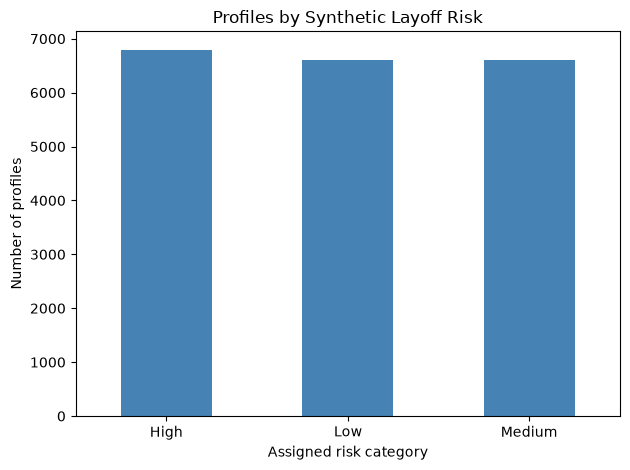

In [4]:
risk_counts = df["Layoff_Risk"].value_counts().sort_index()
display(risk_counts.rename("Profile count").to_frame())

risk_counts.plot(kind="bar", color="steelblue")
plt.title("Profiles by Synthetic Layoff Risk")
plt.xlabel("Assigned risk category")
plt.ylabel("Number of profiles")
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()

## 2. How the risk label relates to key predictors
Because the data are synthetic, `Layoff_Risk` may have been generated from a few predictors. If it was calculated from routine tasks, automation or creativity, the models may simply learn that rule rather than real-world patterns. Check the dataset documentation for how the label was created, and use the tables below to look for clear patterns.

### Average values by risk category
Mean routine task %, tasks automated % and creativity requirement for Low, Medium and High risk profiles.

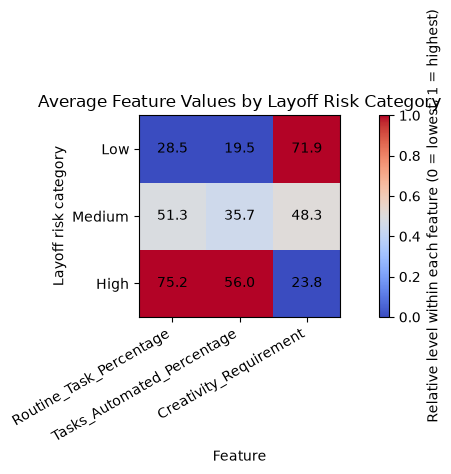

In [7]:
features = [
    "Routine_Task_Percentage",
    "Tasks_Automated_Percentage",
    "Creativity_Requirement"
]

# Average feature values for each risk category
risk_means = df.groupby("Layoff_Risk")[features].mean().reindex(["Low", "Medium", "High"])

# Scale each column 0–1 so colours are comparable across features
colour_values = (risk_means - risk_means.min()) / (risk_means.max() - risk_means.min())

fig, ax = plt.subplots(figsize=(8, 4))
image = ax.imshow(colour_values, cmap="coolwarm", vmin=0, vmax=1)

ax.set_xticks(range(len(features)))
ax.set_xticklabels(features, rotation=30, ha="right")
ax.set_yticks(range(len(risk_means.index)))
ax.set_yticklabels(risk_means.index)

# Write the actual average in each square
for row in range(len(risk_means.index)):
    for col in range(len(features)):
        ax.text(col, row, f"{risk_means.iloc[row, col]:.1f}",
                ha="center", va="center", fontsize=10)

fig.colorbar(image, ax=ax, label="Relative level within each feature (0 = lowest, 1 = highest)")
ax.set_xlabel("Feature")
ax.set_ylabel("Layoff risk category")
ax.set_title("Average Feature Values by Layoff Risk Category")
plt.tight_layout()
plt.show()

### Risk mix across feature ranges
Each feature is split into four equal-sized groups (quartiles). Each row shows the share of Low, Medium and High risk profiles within that range. A steady shift across the rows suggests the label depends strongly on that feature.

In [6]:
for feature in features:
    feature_groups = pd.qcut(df[feature], q=4, duplicates="drop")

    print(f"Layoff risk by {feature} range:")
    display(pd.crosstab(
        feature_groups,
        df["Layoff_Risk"],
        normalize="index"
    ).round(2))

Layoff risk by Routine_Task_Percentage range:


Layoff_Risk,High,Low,Medium
Routine_Task_Percentage,,,
"(9.999, 31.0]",0.00,0.82,0.18
"(31.0, 52.0]",0.08,0.37,0.54
"(52.0, 73.0]",0.47,0.09,0.44
"(73.0, 94.0]",0.82,0.01,0.17


Layoff risk by Tasks_Automated_Percentage range:


Layoff_Risk,High,Low,Medium
Tasks_Automated_Percentage,,,
"(3.999, 21.0]",0.00,0.80,0.19
"(21.0, 35.0]",0.11,0.38,0.52
"(35.0, 51.0]",0.46,0.10,0.44
"(51.0, 93.0]",0.81,0.01,0.18


Layoff risk by Creativity_Requirement range:


Layoff_Risk,High,Low,Medium
Creativity_Requirement,,,
"(-0.001, 27.0]",0.80,0.01,0.19
"(27.0, 48.0]",0.44,0.11,0.45
"(48.0, 69.0]",0.09,0.41,0.50
"(69.0, 100.0]",0.00,0.81,0.19


## 3. Split the data and prepare predictors
The data are split 80/20 into training and test sets. The split is stratified, so Low, Medium and High keep similar proportions in both sets. Preprocessing is fitted inside each model pipeline using training data only, so no information leaks from the test set.

In [8]:
TRAIN, TEST = train_test_split(
    df,
    train_size=0.8,
    random_state=42,
    stratify=df["Layoff_Risk"]
)

X_train = TRAIN.drop(columns="Layoff_Risk")
y_train = TRAIN["Layoff_Risk"]
X_test = TEST.drop(columns="Layoff_Risk")
y_test = TEST["Layoff_Risk"]

cat_cols = X_train.select_dtypes(include=["object", "category", "string"]).columns.tolist()
num_cols = X_train.select_dtypes(include="number").columns.tolist()

print("Categorical predictors:", cat_cols)
print("Numeric predictors:", num_cols)

Categorical predictors: ['Education_Level', 'Industry', 'Job_Role', 'Company_Size', 'Job_Level', 'AI_Adoption_Level']
Numeric predictors: ['Age', 'Years_of_Experience', 'Routine_Task_Percentage', 'Creativity_Requirement', 'Human_Interaction_Level', 'Number_of_AI_Tools_Used', 'AI_Usage_Hours_Per_Week', 'Tasks_Automated_Percentage', 'AI_Training_Hours']


### Preprocessing pipeline
`make_preprocessor` fills missing categorical values with the most frequent level and one-hot encodes them, and fills missing numeric values with the median. Numeric values are standardized only when `scale_numeric=True`, which is used for logistic regression (Random Forests don't need scaling).

In [9]:
def make_preprocessor(scale_numeric=False):
    categorical_pipeline = Pipeline([
        ("imputer", SimpleImputer(strategy="most_frequent")),
        ("onehot", OneHotEncoder(handle_unknown="ignore")),
    ])

    numeric_steps = [("imputer", SimpleImputer(strategy="median"))]
    if scale_numeric:
        numeric_steps.append(("scaler", StandardScaler()))
    numeric_pipeline = Pipeline(numeric_steps)

    return ColumnTransformer([
        ("cat", categorical_pipeline, cat_cols),
        ("num", numeric_pipeline, num_cols),
    ])

## 4. Relationships between predictors
These heatmaps use the training set only. They show which predictors carry overlapping information, which matters when reading feature importance later: strongly related predictors can share importance between them. Association does not imply causation.

### Numeric vs. numeric: Pearson correlation
Values range from −1 (perfect negative) to 1 (perfect positive); 0 means no linear relationship.

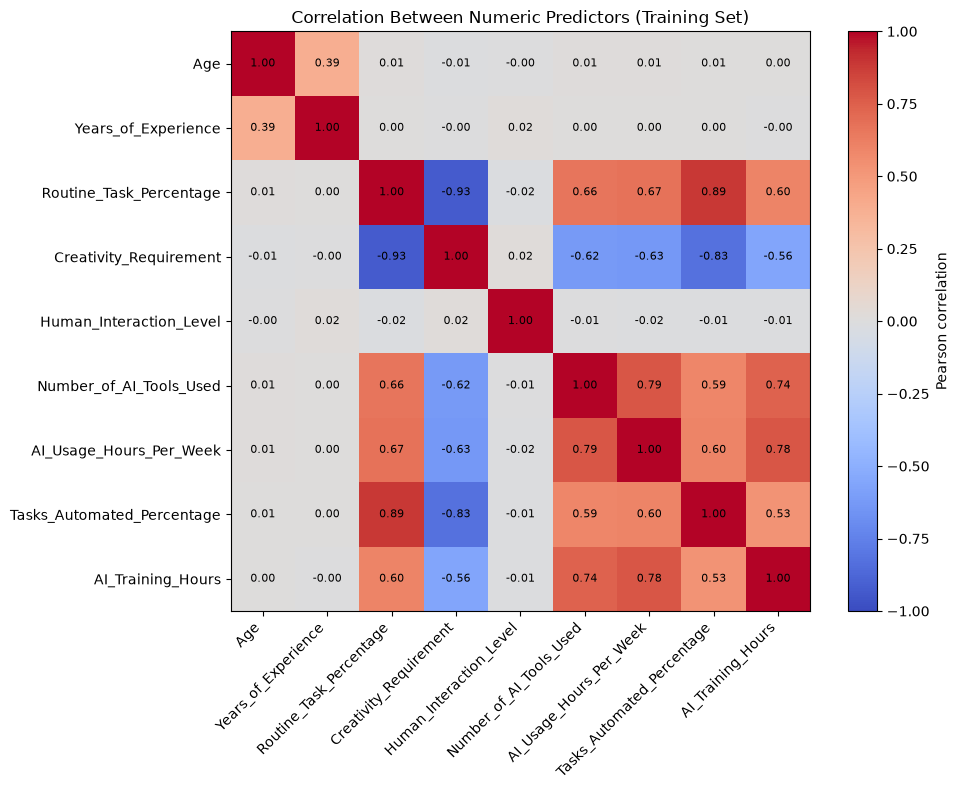

In [10]:
numeric_features = [
    "Age",
    "Years_of_Experience",
    "Routine_Task_Percentage",
    "Creativity_Requirement",
    "Human_Interaction_Level",
    "Number_of_AI_Tools_Used",
    "AI_Usage_Hours_Per_Week",
    "Tasks_Automated_Percentage",
    "AI_Training_Hours",
]

corr_num = X_train[numeric_features].corr()
fig, ax = plt.subplots(figsize=(10, 8))
image = ax.imshow(corr_num, cmap="coolwarm", vmin=-1, vmax=1)

ax.set_xticks(range(len(numeric_features)))
ax.set_xticklabels(numeric_features, rotation=45, ha="right")
ax.set_yticks(range(len(numeric_features)))
ax.set_yticklabels(numeric_features)

for row in range(len(numeric_features)):
    for col in range(len(numeric_features)):
        ax.text(col, row, f"{corr_num.iloc[row, col]:.2f}",
                ha="center", va="center", fontsize=8)

fig.colorbar(image, ax=ax, label="Pearson correlation")
ax.set_title("Correlation Between Numeric Predictors (Training Set)")
plt.tight_layout()
plt.show()

### Categorical vs. categorical: Cramér's V
Values range from 0 (no association) to 1 (perfect association).

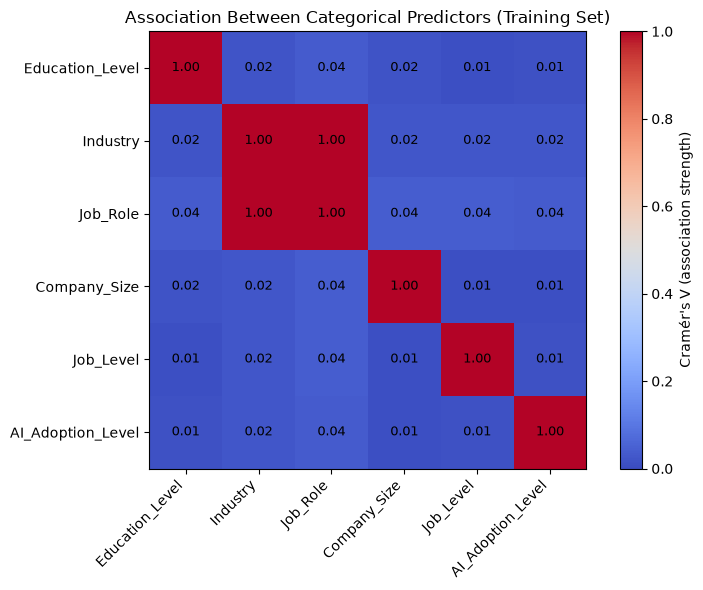

In [11]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy.stats import chi2_contingency

categorical_features = [
    col for col in [
        "Education_Level",
        "Industry",
        "Job_Role",
        "Company_Size",
        "Job_Level",
        "AI_Adoption_Level"
    ]
    if col in X_train.columns
]

def cramers_v(x, y):
    data = pd.DataFrame({"x": x, "y": y}).dropna()
    table = pd.crosstab(data["x"], data["y"])

    if min(table.shape) < 2:
        return np.nan

    chi2 = chi2_contingency(table)[0]
    n = table.to_numpy().sum()
    denominator = n * min(table.shape[0] - 1, table.shape[1] - 1)

    return np.sqrt(chi2 / denominator)

association_cat = pd.DataFrame(
    index=categorical_features,
    columns=categorical_features,
    dtype=float
)

for feature_1 in categorical_features:
    for feature_2 in categorical_features:
        association_cat.loc[feature_1, feature_2] = cramers_v(
            X_train[feature_1],
            X_train[feature_2]
        )

fig, ax = plt.subplots(figsize=(8, 6))
image = ax.imshow(association_cat, cmap="coolwarm", vmin=0, vmax=1)

ax.set_xticks(range(len(categorical_features)))
ax.set_xticklabels(categorical_features, rotation=45, ha="right")
ax.set_yticks(range(len(categorical_features)))
ax.set_yticklabels(categorical_features)

for row in range(len(categorical_features)):
    for col in range(len(categorical_features)):
        ax.text(
            col, row, f"{association_cat.iloc[row, col]:.2f}",
            ha="center", va="center", fontsize=9
        )

fig.colorbar(image, ax=ax, label="Cramér's V (association strength)")
ax.set_title("Association Between Categorical Predictors (Training Set)")
plt.tight_layout()
plt.show()

### Categorical vs. numeric: correlation ratio (η)
Shows how much of a numeric predictor's variation is explained by the categories of a categorical predictor. Values range from 0 to 1.

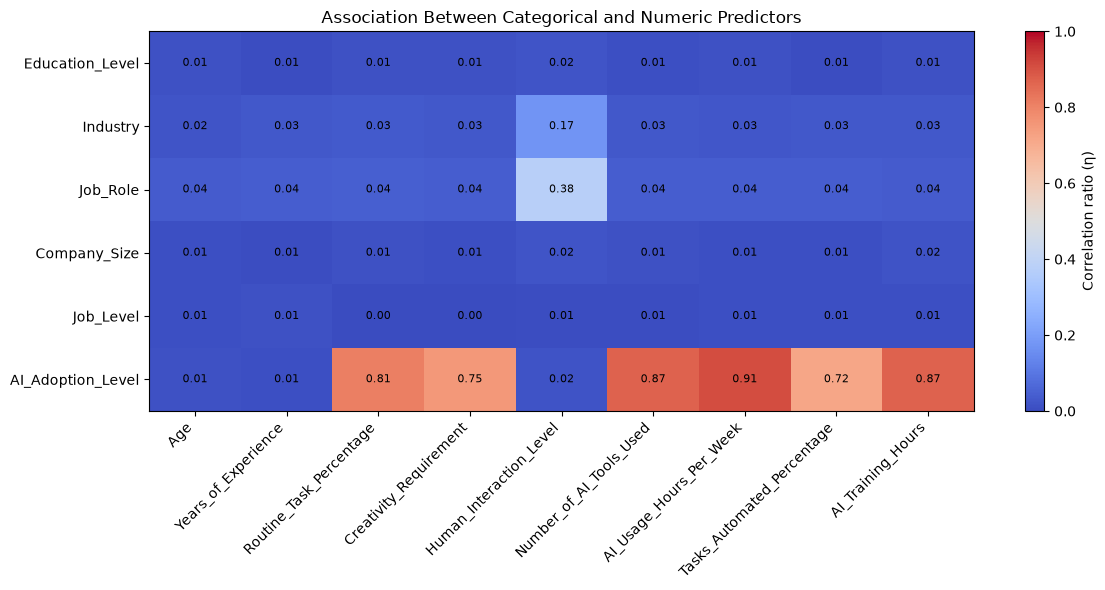

In [12]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

categorical_features = [
    col for col in [
        "Education_Level", "Industry", "Job_Role",
        "Company_Size", "Job_Level", "AI_Adoption_Level"
    ]
    if col in X_train.columns
]

numeric_features = [
    col for col in [
        "Age", "Years_of_Experience", "Routine_Task_Percentage",
        "Creativity_Requirement", "Human_Interaction_Level",
        "Number_of_AI_Tools_Used", "AI_Usage_Hours_Per_Week",
        "Tasks_Automated_Percentage", "AI_Training_Hours"
    ]
    if col in X_train.columns
]

def correlation_ratio(category, number):
    data = pd.DataFrame({"category": category, "number": number}).dropna()

    if data["category"].nunique() < 2:
        return np.nan

    overall_mean = data["number"].mean()
    total_variation = ((data["number"] - overall_mean) ** 2).sum()

    if total_variation == 0:
        return np.nan

    groups = data.groupby("category", observed=True)["number"]
    between_group_variation = sum(
        len(group) * (group.mean() - overall_mean) ** 2
        for _, group in groups
    )

    return np.sqrt(between_group_variation / total_variation)

eta_table = pd.DataFrame(
    index=categorical_features,
    columns=numeric_features,
    dtype=float
)

for category in categorical_features:
    for number in numeric_features:
        eta_table.loc[category, number] = correlation_ratio(
            X_train[category],
            X_train[number]
        )

fig, ax = plt.subplots(figsize=(12, 6))
image = ax.imshow(eta_table.astype(float), cmap="coolwarm", vmin=0, vmax=1,
                  aspect="auto")

ax.set_xticks(range(len(numeric_features)))
ax.set_xticklabels(numeric_features, rotation=45, ha="right")
ax.set_yticks(range(len(categorical_features)))
ax.set_yticklabels(categorical_features)

for row in range(len(categorical_features)):
    for col in range(len(numeric_features)):
        ax.text(col, row, f"{eta_table.iloc[row, col]:.2f}",
                ha="center", va="center", fontsize=8)

fig.colorbar(image, ax=ax, label="Correlation ratio (η)")
ax.set_title("Association Between Categorical and Numeric Predictors")
plt.tight_layout()
plt.show()

## 5. ANOVA: numeric predictors by risk category
One-way ANOVA tests whether the average of each numeric predictor differs across the Low, Medium and High groups, using the full dataset. Because seven predictors are tested, p-values are Bonferroni-adjusted (multiplied by 7 and capped at 1). A small adjusted p-value means at least one group mean differs; it does not show which groups differ.

In [13]:
anova_features = [
    "Age",
    "Years_of_Experience",
    "Routine_Task_Percentage",
    "Number_of_AI_Tools_Used",
    "AI_Usage_Hours_Per_Week",
    "Tasks_Automated_Percentage",
    "AI_Training_Hours",
]
risk_labels = ["Low", "Medium", "High"]
anova_rows = []

for feature in anova_features:
    groups = [
        df.loc[df["Layoff_Risk"] == risk, feature].dropna()
        for risk in risk_labels
    ]
    f_stat, p_value = f_oneway(*groups)
    anova_rows.append({
        "Feature": feature,
        "F statistic": f_stat,
        "p-value": p_value,
    })

anova_table = pd.DataFrame(anova_rows)
anova_table["Adjusted p-value"] = (
    anova_table["p-value"] * len(anova_features)
).clip(upper=1)

anova_display = anova_table.copy()
for column in ["p-value", "Adjusted p-value"]:
    anova_display[column] = anova_display[column].map(
        lambda value: "<0.001" if value < 0.001 else f"{value:.3f}"
    )
anova_display["F statistic"] = anova_display["F statistic"].round(3)

display(anova_display)

,Feature,F statistic,p-value,Adjusted p-value
0,Age,13.618,<0.001,<0.001
1,Years_of_Experience,102.244,<0.001,<0.001
2,Routine_Task_Percentage,15645.384,<0.001,<0.001
3,Number_of_AI_Tools_Used,3388.995,<0.001,<0.001
4,AI_Usage_Hours_Per_Week,3492.869,<0.001,<0.001
5,Tasks_Automated_Percentage,12776.841,<0.001,<0.001
6,AI_Training_Hours,2339.506,<0.001,<0.001


## 6. Train the models
Three models are fitted on the training set:
- **Random Forest** (primary model): 200 trees, numeric predictors not scaled.
- **Logistic regression** (comparison model): numeric predictors standardized.
- **Majority-class baseline**: always predicts the most common training label. Any useful model should beat it.

In [14]:
rf_model = Pipeline([
    ("prep", make_preprocessor(scale_numeric=False)),
    ("clf", RandomForestClassifier(
        n_estimators=200,
        random_state=42,
        n_jobs=-1
    )),
])

log_model = Pipeline([
    ("prep", make_preprocessor(scale_numeric=True)),
    ("clf", LogisticRegression(max_iter=1000)),
])

baseline = DummyClassifier(strategy="most_frequent")

rf_model.fit(X_train, y_train)
log_model.fit(X_train, y_train)
baseline.fit(X_train, y_train)

,"strategy strategy: {""most_frequent"", ""prior"", ""stratified"", ""uniform"", ""constant""}, default=""prior""Strategy to use to generate predictions.* ""most_frequent"": the `predict` method always returns the most frequent class label in the observed `y` argument passed to `fit`. The `predict_proba` method returns the matching one-hot encoded vector.* ""prior"": the `predict` method always returns the most frequent class label in the observed `y` argument passed to `fit` (like ""most_frequent""). ``predict_proba`` always returns the empirical class distribution of `y` also known as the empirical class prior distribution.* ""stratified"": the `predict_proba` method randomly samples one-hot vectors from a multinomial distribution parametrized by the empirical class prior probabilities. The `predict` method returns the class label which got probability one in the one-hot vector of `predict_proba`. Each sampled row of both methods is therefore independent and identically distributed.* ""uniform"": generates predictions uniformly at random from the list of unique classes observed in `y`, i.e. each class has equal probability.* ""constant"": always predicts a constant label that is provided by the user. This is useful for metrics that evaluate a non-majority class. .. versionchanged:: 0.24 The default value of `strategy` has changed to ""prior"" in version 0.24.",'most_frequent'
,"random_state random_state: int, RandomState instance or None, default=NoneControls the randomness to generate the predictions when``strategy='stratified'`` or ``strategy='uniform'``.Pass an int for reproducible output across multiple function calls.See :term:`Glossary <random_state>`.",None
,"constant constant: int or str or array-like of shape (n_outputs,), default=NoneThe explicit constant as predicted by the ""constant"" strategy. Thisparameter is useful only for the ""constant"" strategy.",None
Name,Type,Value
"class_prior_ class_prior_: ndarray of shape (n_classes,) or list of such arraysFrequency of each class observed in `y`. For multioutput classificationproblems, this is computed independently for each output.","ndarray[float64](3,)","[0.34,0.33,0.33]"
"classes_ classes_: ndarray of shape (n_classes,) or list of such arraysUnique class labels observed in `y`. For multi-output classificationproblems, this attribute is a list of arrays as each output has anindependent set of possible classes.","ndarray[object](3,)","['High','Low','Medium']"
"feature_names_in_ feature_names_in_: ndarray of shape (`n_features_in_`,)Names of features seen during :term:`fit`. Defined only when `X` hasfeature names that are all strings.","ndarray[object](15,)","['Age','Education_Level','Years_of_Experience',..., 'AI_Usage_Hours_Per_Week','Tasks_Automated_Percentage', 'AI_Training_Hours']"
n_classes_ n_classes_: int or list of intNumber of label for each output.,int,3
n_features_in_ n_features_in_: intNumber of features seen during :term:`fit`.,int,15
n_outputs_ n_outputs_: intNumber of outputs.,int,1
sparse_output_ sparse_output_: boolTrue if the array returned from predict is to be in sparse CSC format.Is automatically set to True if the input `y` is passed in sparseformat.,bool,False


## 7. Compare test-set performance
All three models are scored on the held-out test set. Macro-averaged precision, recall and F1 give Low, Medium and High equal weight, so a model can't score well just by doing well on the largest category.

In [15]:
models = {
    "Majority-class baseline": baseline,
    "Logistic regression": log_model,
    "Random forest": rf_model,
}

comparison_rows = []
for name, fitted_model in models.items():
    predictions = fitted_model.predict(X_test)
    comparison_rows.append({
        "Model": name,
        "Accuracy": accuracy_score(y_test, predictions),
        "Macro precision": precision_score(
            y_test, predictions, average="macro", zero_division=0
        ),
        "Macro recall": recall_score(
            y_test, predictions, average="macro", zero_division=0
        ),
        "Macro F1": f1_score(
            y_test, predictions, average="macro", zero_division=0
        ),
    })

comparison = pd.DataFrame(comparison_rows).set_index("Model")
display(comparison.round(3))

,Accuracy,Macro precision,Macro recall,Macro F1
Model,,,,
Majority-class baseline,0.340,0.113,0.333,0.169
Logistic regression,0.938,0.938,0.938,0.938
Random forest,0.906,0.906,0.906,0.906


## 8. Random Forest evaluation

### Training vs. test results
Classification reports and confusion matrices for the training and test sets. A much higher training score than test score suggests overfitting.

Training classification report:
              precision    recall  f1-score   support

        High       1.00      1.00      1.00      5437
         Low       1.00      1.00      1.00      5282
      Medium       1.00      1.00      1.00      5281

    accuracy                           1.00     16000
   macro avg       1.00      1.00      1.00     16000
weighted avg       1.00      1.00      1.00     16000

Test classification report:
              precision    recall  f1-score   support

        High       0.93      0.93      0.93      1360
         Low       0.93      0.93      0.93      1320
      Medium       0.86      0.86      0.86      1320

    accuracy                           0.91      4000
   macro avg       0.91      0.91      0.91      4000
weighted avg       0.91      0.91      0.91      4000



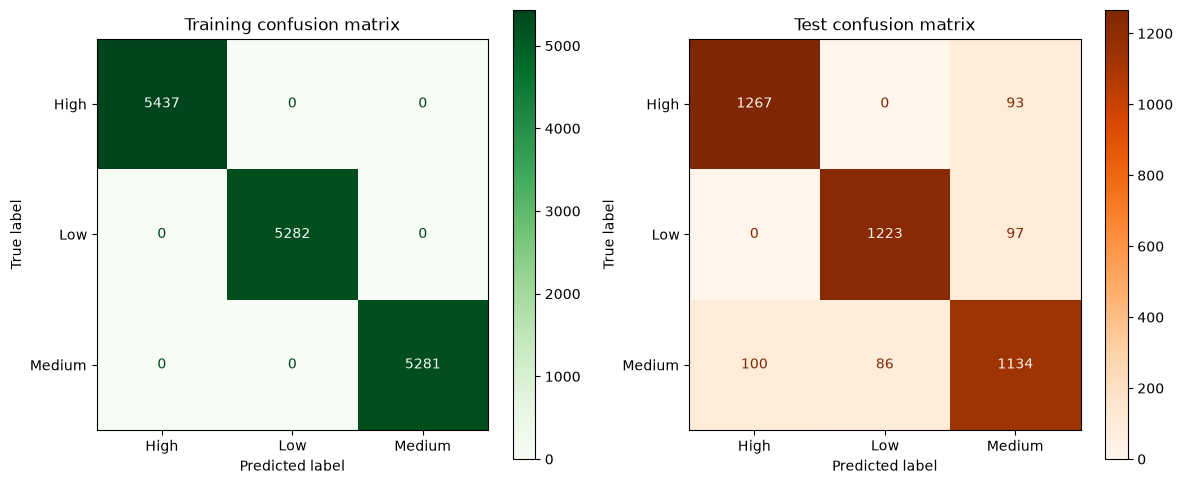

In [18]:
rf_train_predictions = rf_model.predict(X_train)
rf_test_predictions = rf_model.predict(X_test)

print("Training classification report:")
print(classification_report(y_train, rf_train_predictions, zero_division=0))

print("Test classification report:")
print(classification_report(y_test, rf_test_predictions, zero_division=0))

class_labels = rf_model.named_steps["clf"].classes_
fig, axes = plt.subplots(1, 2, figsize=(12, 5))

ConfusionMatrixDisplay.from_predictions(
    y_train, rf_train_predictions,
    labels=class_labels,
    display_labels=class_labels,
    cmap="Greens",
    ax=axes[0]
)
axes[0].set_title("Training confusion matrix")

ConfusionMatrixDisplay.from_predictions(
    y_test, rf_test_predictions,
    labels=class_labels,
    display_labels=class_labels,
    cmap="Oranges",
    ax=axes[1]
)
axes[1].set_title("Test confusion matrix")

plt.tight_layout()
plt.show()

### Which risk categories does the model miss?
The test-set results again, with categories ordered Low → Medium → High. Look at precision and recall for each category separately, since overall accuracy can hide weak performance on one of them.

              precision    recall  f1-score   support

         Low       0.93      0.93      0.93      1320
      Medium       0.86      0.86      0.86      1320
        High       0.93      0.93      0.93      1360

    accuracy                           0.91      4000
   macro avg       0.91      0.91      0.91      4000
weighted avg       0.91      0.91      0.91      4000



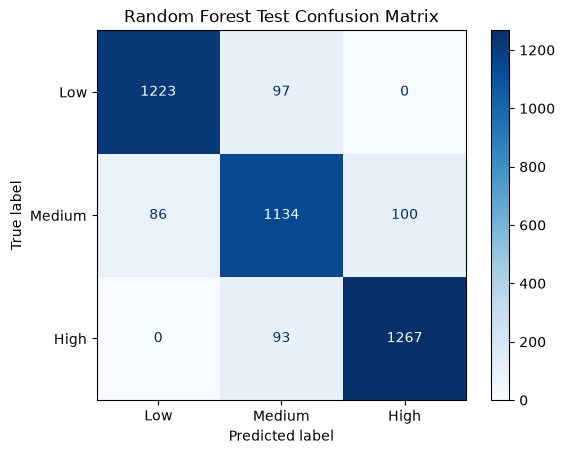

In [17]:
from sklearn.metrics import classification_report, ConfusionMatrixDisplay
import matplotlib.pyplot as plt

test_predictions = rf_model.predict(X_test)

print(classification_report(
    y_test,
    test_predictions,
    labels=["Low", "Medium", "High"],
    zero_division=0
))

ConfusionMatrixDisplay.from_predictions(
    y_test,
    test_predictions,
    labels=["Low", "Medium", "High"],
    display_labels=["Low", "Medium", "High"],
    cmap="Blues"
)

plt.title("Random Forest Test Confusion Matrix")
plt.show()

## 9. Stability and tuning checks

### Cross-validation stability
5-fold stratified cross-validation on the training set. Similar macro F1 scores across folds mean the results don't depend on one particular split.

In [19]:
from sklearn.model_selection import StratifiedKFold, cross_val_score

cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)

scores = cross_val_score(
    rf_model,       # Replace with your fitted Random Forest pipeline's name
    X_train,
    y_train,
    cv=cv,
    scoring="f1_macro"
)

print("F1 score for each fold:", scores.round(3))
print("Average F1:", round(scores.mean(), 3))
print("Variation across folds:", round(scores.std(), 3))

F1 score for each fold: [0.883 0.896 0.897 0.895 0.896]
Average F1: 0.893
Variation across folds: 0.005


### Split criterion: Gini vs. entropy
The first cell shows the two Random Forest settings being compared, for reference only (the models are created but not trained). The second cell copies the main Random Forest pipeline, changes only the split criterion, and reports test accuracy, macro F1, per-category results and a confusion matrix for each.

In [20]:
RandomForestClassifier(
    n_estimators=200,
    criterion="gini",  # Change to "entropy" to compare
    random_state=42,
    class_weight="balanced"
)

RandomForestClassifier(
    n_estimators=200,
    criterion="entropy",  # Change to "entropy" to compare
    random_state=42,
    class_weight="balanced"
)

,"n_estimators n_estimators: int, default=100The number of trees in the forest... versionchanged:: 0.22 The default value of ``n_estimators`` changed from 10 to 100 in 0.22.",200
,"criterion criterion: {""gini"", ""entropy"", ""log_loss""}, default=""gini""The function to measure the quality of a split. Supported criteria are""gini"" for the Gini impurity and ""log_loss"" and ""entropy"" both for theShannon information gain, see :ref:`tree_mathematical_formulation`.Note: This parameter is tree-specific.",'entropy'
,"random_state random_state: int, RandomState instance or None, default=NoneControls both the randomness of the bootstrapping of the samples usedwhen building trees (if ``bootstrap=True``) and the sampling of thefeatures to consider when looking for the best split at each node(if ``max_features < n_features``).See :term:`Glossary <random_state>` for details.",42
,"class_weight class_weight: {""balanced"", ""balanced_subsample""}, dict or list of dicts, default=NoneWeights associated with classes in the form ``{class_label: weight}``.If not given, all classes are supposed to have weight one. Formulti-output problems, a list of dicts can be provided in the sameorder as the columns of y.Note that for multioutput (including multilabel) weights should bedefined for each class of every column in its own dict. For example,for four-class multilabel classification weights should be[{0: 1, 1: 1}, {0: 1, 1: 5}, {0: 1, 1: 1}, {0: 1, 1: 1}] instead of[{1:1}, {2:5}, {3:1}, {4:1}].The ""balanced"" mode uses the values of y to automatically adjustweights inversely proportional to class frequencies in the input dataas ``n_samples / (n_classes * np.bincount(y))``The ""balanced_subsample"" mode is the same as ""balanced"" except thatweights are computed based on the bootstrap sample for every treegrown.For multi-output, the weights of each column of y will be multiplied.Note that these weights will be multiplied with sample_weight (passedthrough the fit method) if sample_weight is specified.",'balanced'
,"max_depth max_depth: int, default=NoneThe maximum depth of the tree. If None, then nodes are expanded untilall leaves are pure or until all leaves contain less thanmin_samples_split samples.",None
,"min_samples_split min_samples_split: int or float, default=2The minimum number of samples required to split an internal node:- If int, then consider `min_samples_split` as the minimum number.- If float, then `min_samples_split` is a fraction and `ceil(min_samples_split * n_samples)` are the minimum number of samples for each split... versionchanged:: 0.18 Added float values for fractions.",2
,"min_samples_leaf min_samples_leaf: int or float, default=1The minimum number of samples required to be at a leaf node.A split point at any depth will only be considered if it leaves atleast ``min_samples_leaf`` training samples in each of the left andright branches. This may have the effect of smoothing the model,especially in regression.- If int, then consider `min_samples_leaf` as the minimum number.- If float, then `min_samples_leaf` is a fraction and `ceil(min_samples_leaf * n_samples)` are the minimum number of samples for each node... versionchanged:: 0.18 Added float values for fractions.",1
,"min_weight_fraction_leaf min_weight_fraction_leaf: float, default=0.0The minimum weighted fraction of the sum total of weights (of allthe input samples) required to be at a leaf node. Samples haveequal weight when sample_weight is not provided.",0.0
,"max_features max_features: {""sqrt"", ""log2"", None}, int or float, default=""sqrt""The number of features to consider when looking for the best split:- If int, then consider `max_features` features at each split.- If float, then `max_features` is a fraction and `max(1, int(max_features * n_features_in_))` features are considered at each split.- If ""sqrt"", then `max_features=sqrt(n_features)`.- If ""log2"", then `max_features=log2(n_features)`.- If None, then `max_features=n_features`... versionchanged::

In [21]:
from sklearn.base import clone
from sklearn.metrics import (
    accuracy_score,
    f1_score,
    classification_report,
    confusion_matrix
)

labels = ["Low", "Medium", "High"]
results = {}

for criterion in ["gini", "entropy"]:
    current_model = clone(rf_model)

    # Find the name of the classifier step in your pipeline
    classifier_step = list(current_model.named_steps.keys())[-1]

    current_model.set_params(
        **{f"{classifier_step}__criterion": criterion}
    )

    current_model.fit(X_train, y_train)
    predictions = current_model.predict(X_test)
    results[criterion] = current_model

    print(f"\n--- Random Forest using {criterion} ---")
    print("Accuracy:", round(accuracy_score(y_test, predictions), 3))
    print("Macro F1:", round(
        f1_score(y_test, predictions, average="macro"), 3
    ))
    print("\nClass-by-class results:")
    print(classification_report(
        y_test, predictions, labels=labels, zero_division=0
    ))
    print("Confusion matrix (rows = actual, columns = predicted):")
    print(confusion_matrix(y_test, predictions, labels=labels))


--- Random Forest using gini ---
Accuracy: 0.906
Macro F1: 0.906

Class-by-class results:
              precision    recall  f1-score   support

         Low       0.93      0.93      0.93      1320
      Medium       0.86      0.86      0.86      1320
        High       0.93      0.93      0.93      1360

    accuracy                           0.91      4000
   macro avg       0.91      0.91      0.91      4000
weighted avg       0.91      0.91      0.91      4000

Confusion matrix (rows = actual, columns = predicted):
[[1223   97    0]
 [  86 1134  100]
 [   0   93 1267]]

--- Random Forest using entropy ---
Accuracy: 0.909
Macro F1: 0.908

Class-by-class results:
              precision    recall  f1-score   support

         Low       0.93      0.93      0.93      1320
      Medium       0.86      0.86      0.86      1320
        High       0.93      0.94      0.93      1360

    accuracy                           0.91      4000
   macro avg       0.91      0.91      0.91      400

### Features per split: out-of-bag check
Compares `max_features=1.0` (all features considered at each split) with `"sqrt"` (a random subset), using 500 trees. Scores come from out-of-bag samples (training rows each tree didn't see), so the test set isn't used for tuning.

In [22]:
import numpy as np
from sklearn.base import clone
from sklearn.metrics import accuracy_score, f1_score

for max_features in [1.0, "sqrt"]:
    current_model = clone(rf_model)

    # Find the Random Forest step in the pipeline
    forest_step = list(current_model.named_steps.keys())[-1]

    current_model.set_params(**{
        f"{forest_step}__max_features": max_features,
        f"{forest_step}__oob_score": True,
        f"{forest_step}__bootstrap": True,
        f"{forest_step}__n_estimators": 500
    })

    current_model.fit(X_train, y_train)
    forest = current_model.named_steps[forest_step]

    # Calculate macro F1 from the forest's out-of-bag predictions
    oob_probs = forest.oob_decision_function_
    valid_rows = np.isfinite(oob_probs).all(axis=1)
    oob_predictions = forest.classes_[oob_probs[valid_rows].argmax(axis=1)]

    print(f"\nmax_features={max_features}")
    print("OOB accuracy:", round(forest.oob_score_, 3))
    print("OOB macro F1:", round(
        f1_score(
            np.asarray(y_train)[valid_rows],
            oob_predictions,
            average="macro"
        ),
        3
    ))


max_features=1.0
OOB accuracy: 0.902
OOB macro F1: 0.902

max_features=sqrt
OOB accuracy: 0.9
OOB macro F1: 0.9


## 10. Feature importance
Two ways of ranking which predictors the Random Forest relies on.

### Built-in Random Forest importance
How much each encoded feature reduces impurity across all trees, based on the training data. Categorical predictors appear as separate one-hot levels (for example, each job role on its own). This measure can favour features with many levels.

,Importance
Routine_Task_Percentage,0.1673
Tasks_Automated_Percentage,0.1442
Creativity_Requirement,0.1240
Human_Interaction_Level,0.0525
AI_Usage_Hours_Per_Week,0.0427
Job_Level_Senior,0.0407
Years_of_Experience,0.0387
AI_Training_Hours,0.0380
AI_Adoption_Level_Low,0.0323
Job_Level_Entry,0.0318


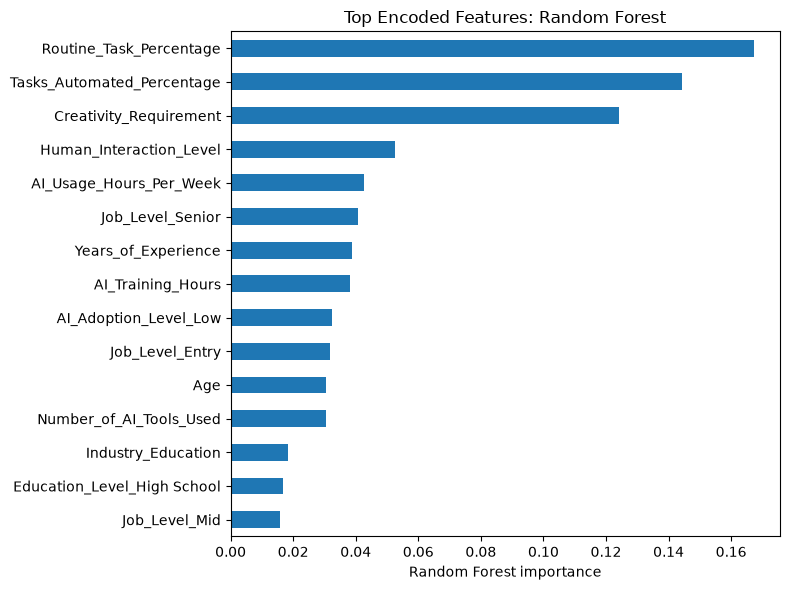

In [23]:
rf_prep = rf_model.named_steps["prep"]
encoded_names = rf_prep.get_feature_names_out()
encoded_names = [name.replace("cat__", "").replace("num__", "") for name in encoded_names]

built_in_importance = pd.Series(
    rf_model.named_steps["clf"].feature_importances_,
    index=encoded_names,
    name="Importance"
).sort_values(ascending=False)

display(built_in_importance.head(20).round(4).to_frame())

built_in_importance.head(15).sort_values().plot(kind="barh", figsize=(8, 6))
plt.xlabel("Random Forest importance")
plt.title("Top Encoded Features: Random Forest")
plt.tight_layout()
plt.show()

### Permutation importance on the test set
Each original predictor is shuffled 10 times and the drop in test macro F1 is recorded. Bigger drops mean the model relies more on that predictor. Because it uses held-out data and the original (not encoded) predictors, this is the more reliable ranking here.

,Feature,Mean F1 decrease,Variation
6,Job_Level,0.178,0.003
7,Routine_Task_Percentage,0.125,0.004
3,Industry,0.096,0.003
13,Tasks_Automated_Percentage,0.088,0.003
1,Education_Level,0.069,0.004
8,Creativity_Requirement,0.055,0.004
9,Human_Interaction_Level,0.045,0.003
2,Years_of_Experience,0.027,0.002
4,Job_Role,0.012,0.002
14,AI_Training_Hours,0.005,0.002


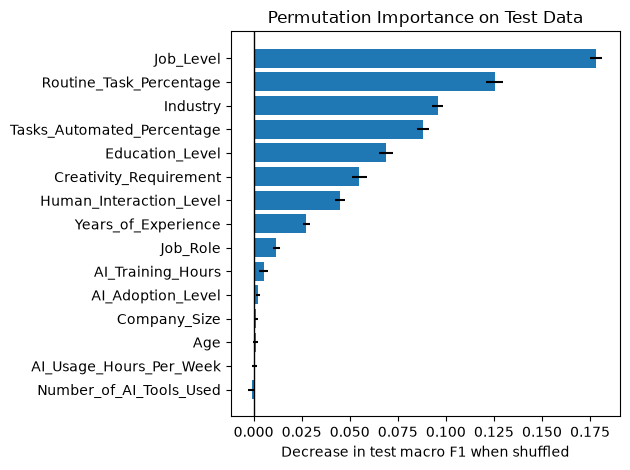

In [24]:
permutation = permutation_importance(
    rf_model,
    X_test,
    y_test,
    scoring="f1_macro",
    n_repeats=10,
    random_state=42,
    n_jobs=-1
)

permutation_table = pd.DataFrame({
    "Feature": X_test.columns,
    "Mean F1 decrease": permutation.importances_mean,
    "Variation": permutation.importances_std,
}).sort_values("Mean F1 decrease", ascending=False)

display(permutation_table.round(3))

top_permutation = permutation_table.head(15).sort_values("Mean F1 decrease")
plt.barh(
    top_permutation["Feature"],
    top_permutation["Mean F1 decrease"],
    xerr=top_permutation["Variation"]
)
plt.axvline(0, color="black", linewidth=1)
plt.xlabel("Decrease in test macro F1 when shuffled")
plt.title("Permutation Importance on Test Data")
plt.tight_layout()
plt.show()

## 11. SHAP explanations by risk category
SHAP shows how each feature pushes individual predictions toward or away from a given risk category, using a sample of up to 300 test profiles. In each plot, features are ranked by overall impact; each dot is one profile, coloured by the feature's value (red = high, blue = low). Categorical predictors appear as one-hot encoded levels.

These plots explain the model's behaviour on synthetic labels; they do not establish causes of real layoffs.

### High risk

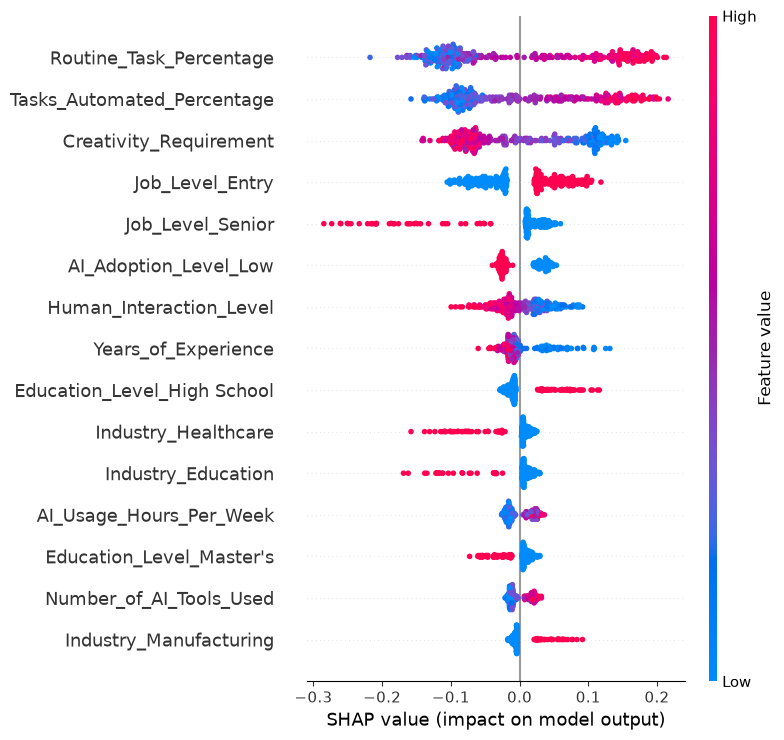

In [25]:
import shap

# Explain a sample of test profiles to keep the calculation manageable.
X_shap_raw = X_test.sample(n=min(300, len(X_test)), random_state=42)
X_shap_transformed = rf_prep.transform(X_shap_raw)
if hasattr(X_shap_transformed, "toarray"):
    X_shap_transformed = X_shap_transformed.toarray()

X_shap = pd.DataFrame(
    X_shap_transformed,
    columns=encoded_names,
    index=X_shap_raw.index
)

explainer = shap.TreeExplainer(rf_model.named_steps["clf"])
shap_values = explainer.shap_values(X_shap)

risk_category = "High"
class_index = list(class_labels).index(risk_category)

# Support both SHAP's older list output and its newer multi-class array output.
if isinstance(shap_values, list):
    class_shap_values = shap_values[class_index]
else:
    class_shap_values = shap_values[:, :, class_index]

shap.summary_plot(class_shap_values, X_shap, max_display=15)

### Medium risk

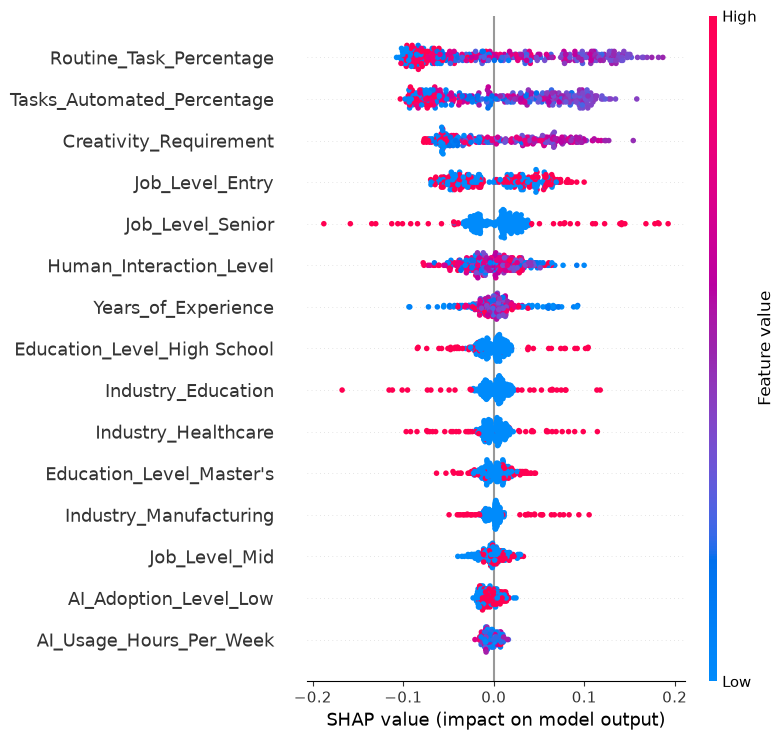

In [15]:
import shap

# Explain a sample of test profiles to keep the calculation manageable.
X_shap_raw = X_test.sample(n=min(300, len(X_test)), random_state=42)
X_shap_transformed = rf_prep.transform(X_shap_raw)
if hasattr(X_shap_transformed, "toarray"):
    X_shap_transformed = X_shap_transformed.toarray()

X_shap = pd.DataFrame(
    X_shap_transformed,
    columns=encoded_names,
    index=X_shap_raw.index
)

explainer = shap.TreeExplainer(rf_model.named_steps["clf"])
shap_values = explainer.shap_values(X_shap)

risk_category = "Medium"
class_index = list(class_labels).index(risk_category)

# Support both SHAP's older list output and its newer multi-class array output.
if isinstance(shap_values, list):
    class_shap_values = shap_values[class_index]
else:
    class_shap_values = shap_values[:, :, class_index]

shap.summary_plot(class_shap_values, X_shap, max_display=15)

### Low risk

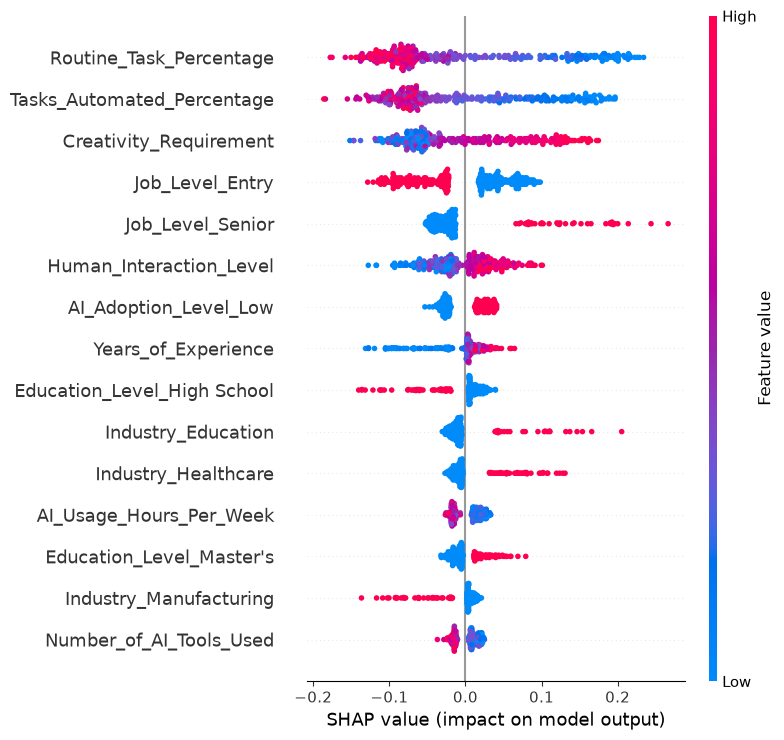

In [16]:
import shap

# Explain a sample of test profiles to keep the calculation manageable.
X_shap_raw = X_test.sample(n=min(300, len(X_test)), random_state=42)
X_shap_transformed = rf_prep.transform(X_shap_raw)
if hasattr(X_shap_transformed, "toarray"):
    X_shap_transformed = X_shap_transformed.toarray()

X_shap = pd.DataFrame(
    X_shap_transformed,
    columns=encoded_names,
    index=X_shap_raw.index
)

explainer = shap.TreeExplainer(rf_model.named_steps["clf"])
shap_values = explainer.shap_values(X_shap)

risk_category = "Low"
class_index = list(class_labels).index(risk_category)

# Support both SHAP's older list output and its newer multi-class array output.
if isinstance(shap_values, list):
    class_shap_values = shap_values[class_index]
else:
    class_shap_values = shap_values[:, :, class_index]

shap.summary_plot(class_shap_values, X_shap, max_display=15)

## 12. Performance by subgroup
Checks whether the Random Forest works equally well for different kinds of profiles. Small groups give less stable estimates, so check the number of profiles in each group.

### Accuracy by subgroup
Share of test profiles classified correctly within each job role, job level, education level, company size and AI adoption level.

In [19]:
subgroup_features = [
    "Job_Role",
    "Job_Level",
    "Education_Level",
    "Company_Size",
    "AI_Adoption_Level"
]

for feature in subgroup_features:
    subgroup_data = pd.DataFrame({
        feature: TEST[feature],
        "Correct": y_test == rf_test_predictions,
    })
    subgroup_summary = subgroup_data.groupby(feature)["Correct"].agg(
        Accuracy="mean",
        Profiles="size"
    )
    subgroup_summary["Accuracy (%)"] = (subgroup_summary["Accuracy"] * 100).round(1)
    print(f"Accuracy by {feature}:")
    display(subgroup_summary[["Profiles", "Accuracy (%)"]].sort_values("Accuracy (%)"))

Accuracy by Job_Role:


,Profiles,Accuracy (%)
Job_Role,,
Production Supervisor,162,84.6
Academic Coordinator,158,85.4
Teacher,143,86.0
Data Analyst,158,87.3
Sales Associate,166,88.0
Research Assistant,178,88.8
ML Engineer,170,88.8
Warehouse Manager,170,88.8
Operator,187,89.3


Accuracy by Job_Level:


,Profiles,Accuracy (%)
Job_Level,,
Mid,1635,90.5
Entry,1749,90.6
Senior,616,90.9


Accuracy by Education_Level:


,Profiles,Accuracy (%)
Education_Level,,
PhD,220,83.2
High School,729,88.8
Master's,1068,90.9
Bachelor's,1983,91.9


Accuracy by Company_Size:


,Profiles,Accuracy (%)
Company_Size,,
Small,1222,90.0
Large,1024,90.2
Medium,1754,91.2


Accuracy by AI_Adoption_Level:


,Profiles,Accuracy (%)
AI_Adoption_Level,,
Low,2135,90.4
Medium,1591,90.8
High,274,91.6


### Macro F1 and High-risk recall by subgroup
For each industry, job level and education level: accuracy, macro F1, and High-risk recall (the share of truly High-risk profiles the model catches).

In [36]:
import pandas as pd
from sklearn.metrics import accuracy_score, f1_score, recall_score

# Make predictions if you haven't already
test_predictions = rf_model.predict(X_test)

results = X_test[["Industry", "Job_Level", "Education_Level"]].copy()
results["Actual"] = y_test
results["Predicted"] = test_predictions

def compare_groups(data, group_column):
    rows = []

    for group, subset in data.groupby(group_column, dropna=False):
        rows.append({
            group_column: group,
            "Number of records": len(subset),
            "Accuracy": accuracy_score(subset["Actual"], subset["Predicted"]),
            "Macro F1": f1_score(
                subset["Actual"], subset["Predicted"],
                average="macro", zero_division=0
            ),
            "High-risk recall": recall_score(
                subset["Actual"], subset["Predicted"],
                labels=["High"], average="macro", zero_division=0
            )
        })

    return pd.DataFrame(rows).round(3)

display(compare_groups(results, "Industry"))
display(compare_groups(results, "Job_Level"))
display(compare_groups(results, "Education_Level"))

,Industry,Number of records,Accuracy,Macro F1,High-risk recall
0,Education,479,0.868,0.853,0.900
1,Finance,485,0.938,0.937,0.976
2,Healthcare,548,0.911,0.908,0.967
3,IT,486,0.897,0.897,0.993
4,Logistics,501,0.898,0.898,0.918
5,Manufacturing,510,0.894,0.892,0.887
6,Retail,489,0.918,0.915,0.911
7,Telecom,502,0.922,0.923,0.932


,Job_Level,Number of records,Accuracy,Macro F1,High-risk recall
0,Entry,1749,0.906,0.900,0.941
1,Mid,1635,0.905,0.904,0.932
2,Senior,616,0.909,0.880,0.818


,Education_Level,Number of records,Accuracy,Macro F1,High-risk recall
0,Bachelor's,1983,0.919,0.920,0.936
1,High School,729,0.888,0.885,0.888
2,Master's,1068,0.909,0.906,0.965
3,PhD,220,0.832,0.802,0.974


## 13. Alternative Random Forest with balanced class weights
A self-contained version of the workflow. It rebuilds the train/test split and preprocessing, trains a Random Forest with `class_weight="balanced"` (which gives smaller risk categories more weight), checks it with 5-fold stratified cross-validation on the training set, then reports test-set precision, recall, macro F1 and a confusion matrix.

**Run this section last.** It overwrites `df`, `X_train`, `X_test`, `y_train`, `y_test` and `rf_model`, so any cell above that is re-run afterwards would use this model instead.

In [ ]:
import pandas as pd

from sklearn.model_selection import train_test_split, StratifiedKFold, cross_val_score
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import OneHotEncoder
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import classification_report, ConfusionMatrixDisplay
import matplotlib.pyplot as plt

# Separate predictors from the target
df = df.dropna(subset=["Layoff_Risk"])
X = df.drop(columns=["Layoff_Risk"])
y = df["Layoff_Risk"]

# Make training and test sets, keeping risk proportions similar
X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

# Find numeric and categorical columns
numeric_cols = X_train.select_dtypes(include="number").columns
categorical_cols = X_train.select_dtypes(
    include=["object", "category"]
).columns

# Fill missing values; convert text categories into numbers
preprocessor = ColumnTransformer([
    ("numeric", SimpleImputer(strategy="median"), numeric_cols),
    ("categorical", Pipeline([
        ("imputer", SimpleImputer(strategy="most_frequent")),
        ("onehot", OneHotEncoder(handle_unknown="ignore"))
    ]), categorical_cols)
])

# Build the Random Forest pipeline
rf_model = Pipeline([
    ("preprocessor", preprocessor),
    ("classifier", RandomForestClassifier(
        n_estimators=200,
        random_state=42,
        class_weight="balanced"
    ))
])

# Check performance with 5-fold cross-validation on the training set
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)

cv_scores = cross_val_score(
    rf_model,
    X_train,
    y_train,
    cv=cv,
    scoring="f1_macro"
)

print("Cross-validation macro F1 scores:", cv_scores.round(3))
print("Average cross-validation macro F1:", round(cv_scores.mean(), 3))

# Train on the full training set
rf_model.fit(X_train, y_train)

# Evaluate on the test set
test_predictions = rf_model.predict(X_test)

print("\nTest-set results:")
print(classification_report(
    y_test,
    test_predictions,
    labels=["Low", "Medium", "High"],
    zero_division=0
))

ConfusionMatrixDisplay.from_predictions(
    y_test,
    test_predictions,
    labels=["Low", "Medium", "High"],
    display_labels=["Low", "Medium", "High"],
    cmap="Blues"
)

plt.title("Random Forest: Test Confusion Matrix")
plt.show()

## 14. Interpretation and limitations
This notebook evaluates models that predict synthetic labels. High performance or high feature importance may reflect how the labels were generated. Check the dataset documentation for its label-generation method, and do not interpret the results as actual worker layoff risk or causal effects.